# AIML CA1-Part A: Classification

## 1. Loading Data

### 1.1 Importing necessary packages

In [13]:
import pandas as pd
import numpy as np

# installing graphing libraries
%pip install seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# normalization 
from sklearn.preprocessing import StandardScaler, RobustScaler
#PCA
from sklearn.decomposition import PCA

#Train, Test
from sklearn.model_selection import train_test_split

#models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

#hyperparameter tuning
!pip install optuna
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, make_scorer

#matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

Note: you may need to restart the kernel to use updated packages.


### 1.2 Importing datasets

In [3]:
df= pd.read_csv(r"C:\Users\yanmy\AIML_Lab\AIML-CA1-Dataset\factory_data.csv")
df.head()

,Unique ID,Product ID,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
0,1,K12965,M,24.95,35.45,1551.0,42.8,0,0
1,2,Z62710,L,25.05,35.55,1408.0,46.3,3,0
2,3,T20224,L,24.95,35.35,1498.0,49.4,5,0
3,4,Z33024,L,25.05,35.45,1433.0,39.5,7,0
4,5,Z52839,L,25.05,35.55,1408.0,40.0,9,0


### 1.3 Checking data properties

In [4]:
df.shape
df.info()

print("\n\nNumber of missing values in each columns: ")
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unique ID             20000 non-null  int64  
 1   Product ID            20000 non-null  object 
 2   Quality               19009 non-null  object 
 3   Ambient T (C)         20000 non-null  float64
 4   Process T (C)         19600 non-null  float64
 5   Rotation Speed (rpm)  18812 non-null  float64
 6   Torque (Nm)           20000 non-null  float64
 7   Tool Wear (min)       20000 non-null  int64  
 8   Machine Status        20000 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 1.4+ MB


Number of missing values in each columns: 


Unique ID                  0
Product ID                 0
Quality                  991
Ambient T (C)              0
Process T (C)            400
Rotation Speed (rpm)    1188
Torque (Nm)                0
Tool Wear (min)            0
Machine Status             0
dtype: int64

### Reflection: Dataset Overview and Missing Values

This dataset contains 20,000 entries and 9 columns, representing machine performance and status data. Most columns are complete, but several have missing values:

- `Quality`: 991 missing values
- `Process T (C)`: 400 missing values 
- `Rotation Speed (rpm)`: 1,188 missing values

The target variable `Machine Status` has no missing values and is binary, making this a classification problem. The mix of object, float, and integer types indicates that both categorical and numerical handling will be required.

---

---

## 2. EDA

### 2.1 Nature of Target Data

Proportions:
Machine Status
0    0.9661
1    0.0339
Name: proportion, dtype: float64


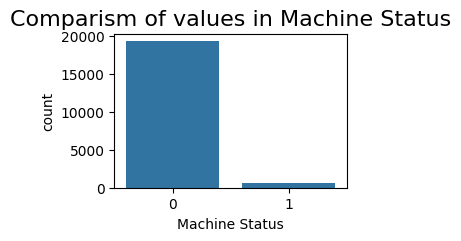

In [5]:
plt.figure(figsize=(3, 2))   
sns.countplot(x='Machine Status', data=df)
plt.title("Comparism of values in Machine Status", fontsize=16)
print("Proportions:")
print(df['Machine Status'].value_counts(normalize=True))
plt.show()

### Reflection: Nature of Target Data

From the count plot and proportion analysis, it's clear that the dataset is highly imbalanced ; approximately 96.6% of the machines are in normal condition, while only 3.4% represent failures.

This imbalance has important implications for modeling, which can give over 90% accurency even in the models which is not working properly. We should avoid using the classifiers which are sensitive to imbalence such as KNN.


### 2.2 Nature of Missing Values

#### Data Cleaning Strategy

- Missing values are analyzed before any modeling to understand data quality.
- No immediate imputation is done here to avoid introducing bias prematurely.
- Cleaning decisions are delayed until after understanding feature distributions in EDA.

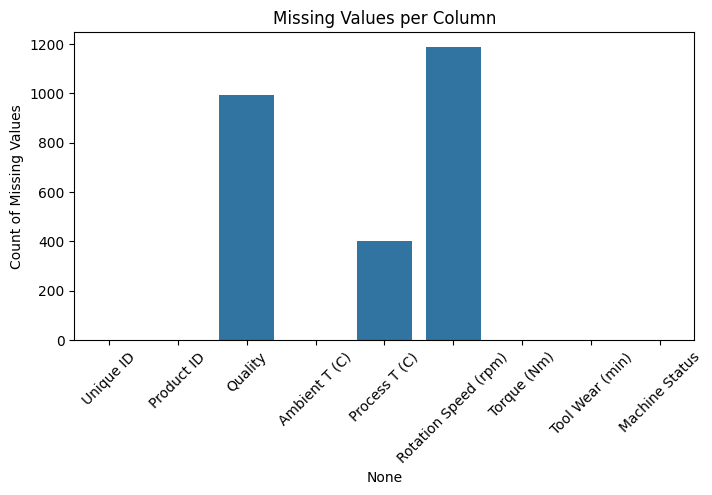

In [6]:
missing_counts = df.isnull().sum()

plt.figure(figsize=(8,4))
sns.barplot(x=missing_counts.index, y=missing_counts.values)
plt.xticks(rotation=45)
plt.title("Missing Values per Column")
plt.ylabel("Count of Missing Values")
plt.show()


### 2.3 Nature of Numerical Feature Distribution

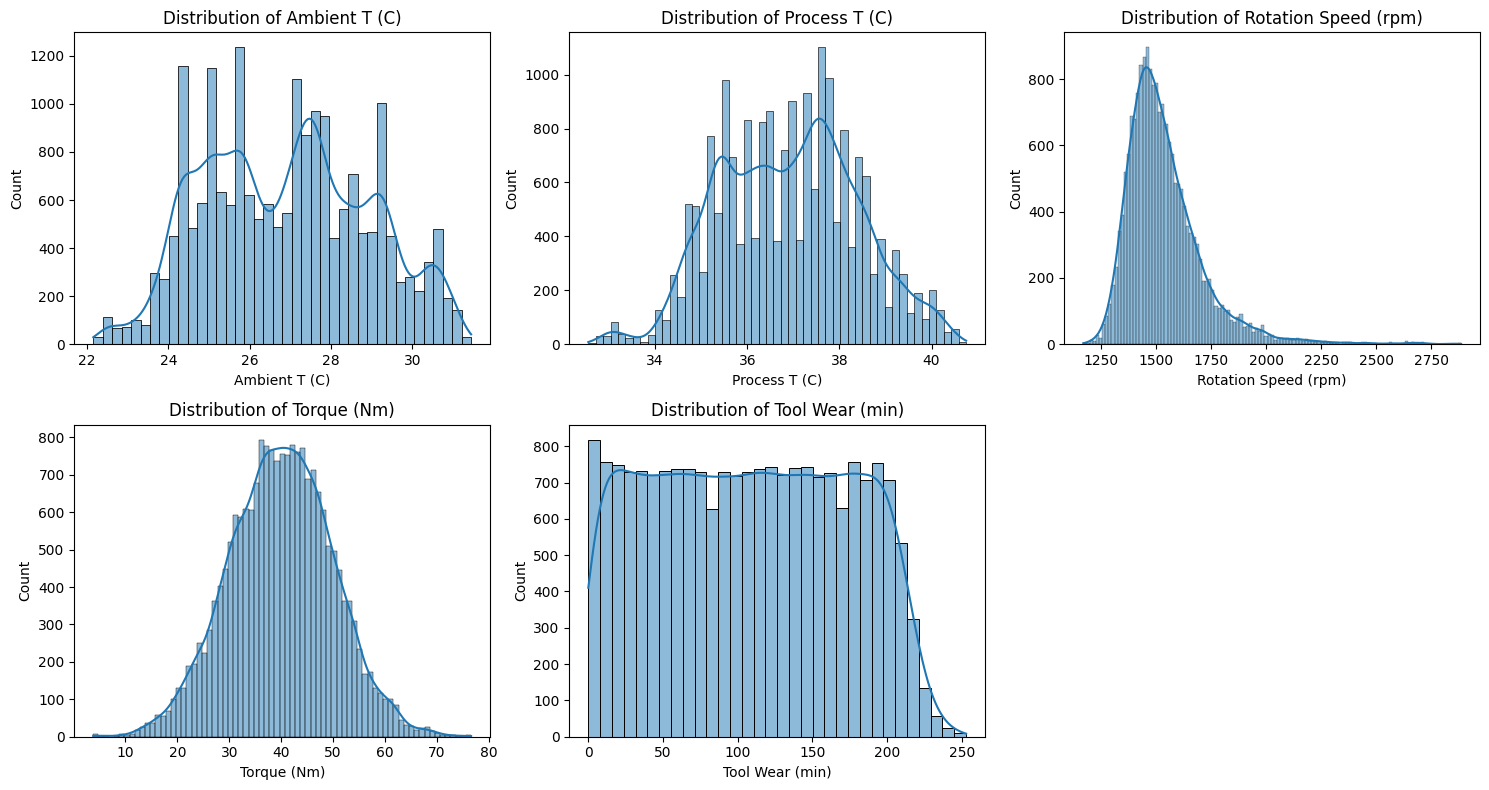

In [7]:
numerical_cols = ['Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 
                  'Torque (Nm)', 'Tool Wear (min)']

#Set up the subplot grid
fig, axes = plt.subplots(2, 3, figsize=(15,8))
#Flatten axes to 1D array for looping
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

#Removing empty subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

### Reflection: Nature of Numerical Feature Distribution

This section shows the shape each numerical feature distribution with KDE. 

---

#### Ambient T (C)
- **Shape:** Roughly normal distribution centered around 23–24°C.
- **Insight:** Ambient temperature is stable and consistent across samples.Likely not a strong discriminator between machine statuses unless combined with other features.

---

#### Process T (C)
- **Shape:** Multimodal — multiple peaks suggest different operating modes or product types.
- **Insight:** Worth checking if certain modes correlate with failures. Could be a strong feature.

---

#### Rotation Speed (rpm)
- **Shape:** Sharp peak around 1500 rpm, possibly a default or standard setting.
- **Insight:** Most machines operate at a consistent speed, but still have outliers.

---

#### Torque (Nm)
- **Shape:** Bell-shaped curve centered around 35 Nm.
- **Insight:** Torque values are tightly clustered, suggesting controlled operation.
- 
---

#### Tool Wear (min)
- **Shape:** Fairly uniform distribution across the range.
- **Insight:** Tool wear varies widely — some tools are fresh, others heavily used.Strong candidate for predicting failure. High wear likely increases risk.

---

### Summary
- **Stable features:** Ambient T and Torque show tight distributions.
- **Variable features:** Process T and Tool Wear show diversity — likely more predictive.

### 2.4 Nature of Categorical Feature Distribution

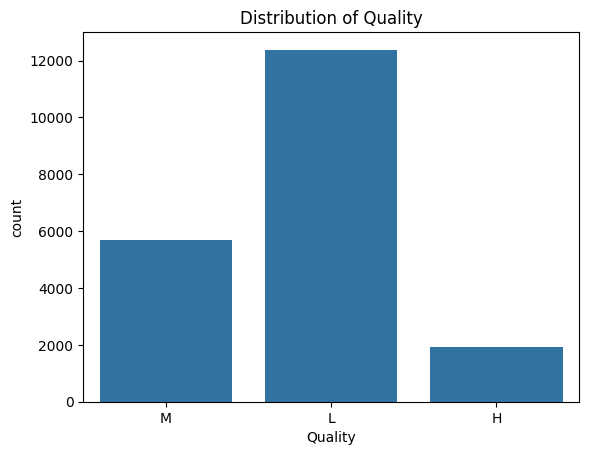

In [49]:
sns.countplot(x='Quality', data=df)
plt.title("Distribution of Quality")
plt.show()

### Reflection: Nature of Categorical Feature Distribution

- The 'Quality' feature has three levels: Low (L), Medium (M), and High (H).
- The distribution is imbalanced:
  - L: ~12,000 samples
  - M: ~6,000 samples
  - H: ~2,000 samples
- This imbalance may affect model learning if 'Quality' is predictive of failure.
- Since the categories are ordered, ordinal encoding is preferred.

### 2.5 Feature–Target Relationships

In [21]:
target = 'Machine Status'
num_cols = ['Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)', 'Tool Wear (min)']
cat_cols = ['Quality'] 

# 1 Target coorlation with numeric features
print("Correlation to target:")
for col in num_cols:
    corr = df[col].corr(df[target])
    print(f"{col}: {corr*100:.2f}%")

# 2 Target coorlation with categorical features
for col in cat_cols:
    print(f"\nFailure rate by {col}:")

    #Group by the column and calculate mean of target
    grouped = df.groupby(col)[target].mean()

    #Sort values from highest to lowest
    grouped = grouped.sort_values(ascending=False)
    for category, rate in grouped.items():
        print(f"  {category}: {rate*100:.2f}%")


Correlation to target:
Ambient T (C): 8.25%
Process T (C): 3.60%
Rotation Speed (rpm): -4.57%
Torque (Nm): 19.13%
Tool Wear (min): 10.54%

Failure rate by Quality:
  L: 3.91%
  M: 2.79%
  H: 2.13%


### Reflection: Feature–Target Relationships

#### Numeric Correlations
- **Torque (Nm)** shows the strongest positive correlation with failure (19%).
- **Tool Wear (min)** also correlates positively (11%).
- **Ambient and Process T** have weak positive correlations.
- **Rotation Speed (rpm)** has a slight negative correlation.

#### Categorical Failure Rates
- Failure rate by 'Quality':
  - L: 3.86%
  - M: 2.79%
  - H: 2.13%
- Machines with lower quality fail more often.
- should be treated as an **ordinal feature** during modeling.

### 2.6 Visualizing relationships of most corrlated features

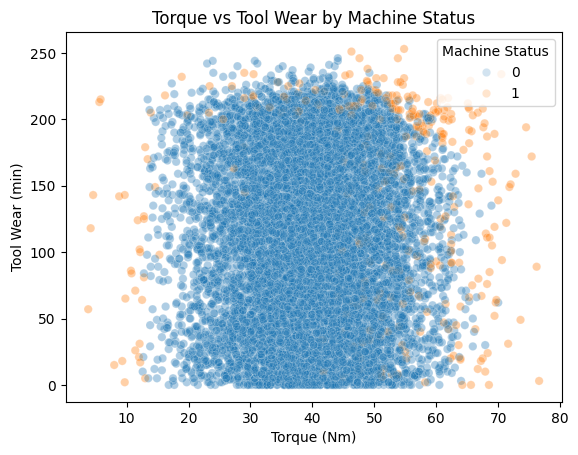

In [34]:
sns.scatterplot(x='Torque (Nm)', y='Tool Wear (min)', hue='Machine Status', data=df, alpha=0.2)
plt.title("Torque vs Tool Wear by Machine Status")
plt.show()

### Reflection: Torque vs Tool Wear by Machine Status

- Most machines operate normally across a wide range of torque and wear.
- Torque is a strong predictor of failure, especially in the outlier range.
- Torque shows a wide spread among failures, suggesting it may interact with wear

### 2.7 Multicollinearity in features

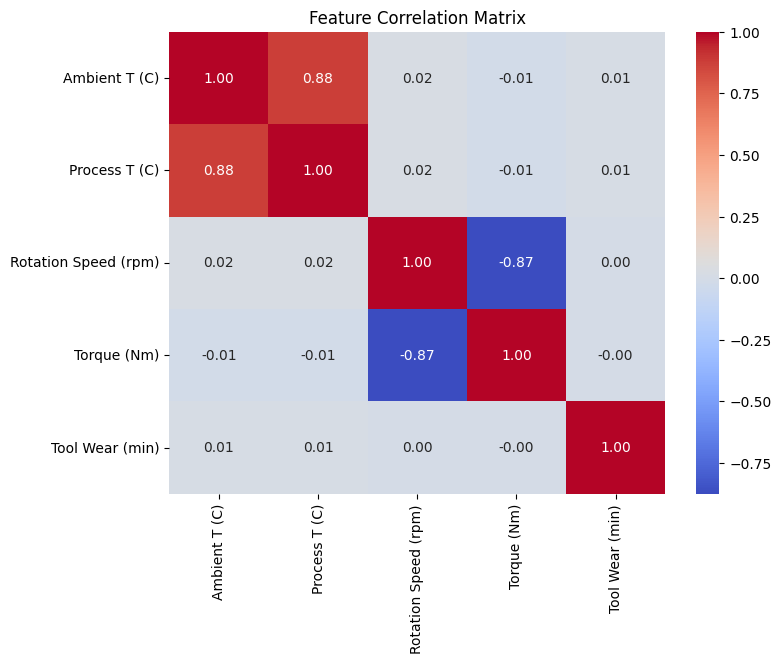

,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min)
Ambient T (C),1.000000,0.876107,0.024601,-0.013774,0.013849
Process T (C),0.876107,1.000000,0.020030,-0.012852,0.013870
Rotation Speed (rpm),0.024601,0.020030,1.000000,-0.874754,0.003145
Torque (Nm),-0.013774,-0.012852,-0.874754,1.000000,-0.003093
Tool Wear (min),0.013849,0.013870,0.003145,-0.003093,1.000000


In [25]:
# Select only numerical features
num_cols = ['Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)', 'Tool Wear (min)']

# Compute correlation matrix
corr_matrix = df[num_cols].corr()

# Plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

corr_matrix

### Reflection: Feature Correlation Matrix

- **Ambient T (C)** and **Process T (C)** show strong positive correlation (+0.87).
- **Rotation Speed (rpm)** and **Torque (Nm)** show strong negative correlation (–0.87).
- Other feature pairs have weak or no correlation.
- So we can reject the data from previous step that Torque and Tool Wear may interact.

#### Modeling Implications
- High correlation may cause multicollinearity in linear models.
- Dropping or combining redundant features should be considered.

### Key EDA Takeaways

- Target feature is highly imbalanced.
- Contains missing values to handle in Rotation Speed, Process T and Quality.
- Ambient T and Torque show tight distributions. Process T and Tool Wear show diversity — likely more predictive.
- The Quality categories are ordered, ordinal encoding should be used.
- Torque (Nm) and Tool Wear shows moderate positive correlation to the target.
- Machines often fail in outlier range of Torque
- Some features should be considered for dropping or combining to avoid multicollinearity.

---

---

## 3. Cleaning Data

In [14]:
#Determining which method to fill

print("Number of unique values in 'Quality' column: ",df['Quality'].nunique())

print("Number of unique values in 'Process T (C)' column: ",df['Process T (C)'].nunique())

print("Number of unique values in 'Rotation Speed (rpm)' column: ",df['Rotation Speed (rpm)'].nunique())

Number of unique values in 'Quality' column:  3
Number of unique values in 'Process T (C)' column:  83
Number of unique values in 'Rotation Speed (rpm)' column:  941


### Relection: Unique Value Analysis
- 'Quality': 3 unique values (categorical)
- 'Process T (C)': 83 unique values (continuous numeric)
- 'Rotation Speed (rpm)': 942 unique values (continuous numeric)

#### Imputation Strategy
- 'Quality': Filled with mode ('L') since it's ordinal and low-cardinality.
- 'Process T (C)': Forward filled ('ffill') due to continuity and similar values across rows.
- 'Rotation Speed (rpm)': Filled with mean due to high variability.


### 3.1 Filling missing values

In [4]:
# Filling 'Quality' column with mode (ordinal categorical)
df['Quality'] = df['Quality'].fillna(df['Quality'].mode().iloc[0])

# Filling 'Process T (C)' column with forward fill (time-like continuity)
df['Process T (C)'] = df['Process T (C)'].ffill()

# Filling 'Rotation Speed (rpm)' column with mean (continuous numeric)
df['Rotation Speed (rpm)'] = df['Rotation Speed (rpm)'].fillna(df['Rotation Speed (rpm)'].mean())

# Check remaining missing values
df.isnull().sum()

Unique ID               0
Product ID              0
Quality                 0
Ambient T (C)           0
Process T (C)           0
Rotation Speed (rpm)    0
Torque (Nm)             0
Tool Wear (min)         0
Machine Status          0
dtype: int64

---

---

## 4. Feature Prepartaion

### 4.1 Changing categorical data to discrete data

In [5]:
# pd.get_dummies is not use as it will create more feature, and Quality data is Ordinal 
df['Quality'] = df['Quality'].map({'L': 0, 'M': 1, 'H': 2})
df.head()

,Unique ID,Product ID,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
0,1,K12965,1,24.95,35.45,1551.0,42.8,0,0
1,2,Z62710,0,25.05,35.55,1408.0,46.3,3,0
2,3,T20224,0,24.95,35.35,1498.0,49.4,5,0
3,4,Z33024,0,25.05,35.45,1433.0,39.5,7,0
4,5,Z52839,0,25.05,35.55,1408.0,40.0,9,0


#### Relection: Encoding

- Converted levels (L, M, H) to numeric values (0, 1, 2).
- This preserves the natural order of categories.

### Rechecking correlation after cleaning data

In [6]:
df_numeric = df.select_dtypes(include='number')
# Get correlation with target and convert to percentage
corr_percent = df_numeric.corr()['Machine Status'] * 100
corr_percent = corr_percent.round(2)

print("Correlation to target:")
print(corr_percent)

Correlation to target:
Unique ID                -1.14
Quality                  -3.43
Ambient T (C)             8.25
Process T (C)             3.59
Rotation Speed (rpm)     -4.45
Torque (Nm)              19.13
Tool Wear (min)          10.54
Machine Status          100.00
Name: Machine Status, dtype: float64


### 4.2 Feature Selection

In [7]:
df = df.drop(['Unique ID', 'Product ID'], axis=1)
print(df.columns.tolist())

['Quality', 'Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)', 'Tool Wear (min)', 'Machine Status']


### Justification: Feature Selection 

- Removed 'Unique ID' and 'Product ID' because they are identifiers.
- These columns uniquely label each machine or product but do not provide any predictive data. 

##### PCA and Normalization will be carried out only after train test split to avoid data leakage

---

---

## 5. Train/Test Split and Data Preparation

### 5.1 Train,Test Split

- Train-test split is done before scaling and PCA to prevent data leakage.
- If preprocessing is done before splitting, information from test data may leak into training.
- This ensures a fair and realistic evaluation of model performance.

In [8]:
X = df.drop('Machine Status', axis=1)   # all columns except target
y = df['Machine Status']                # target column

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,       # keep class distribution
    random_state=42
)

print("Train size:", X_train.shape, "Test size:", X_test.shape)


Train size: (16000, 6) Test size: (4000, 6)


### Justification: Train,Test Split

- The target ('Machine Status') is imbalanced.  
- 'stratify=y' keeps the same class proportions in train and test sets.  
- This prevents biased splits and makes model evaluation more reliable.  

---

### 5.2 Dummy Baseline

#### Why we choose standardized dummy classiffier? 

- The dummy classifier provides a **baseline performance** by making simple predictions (e.g. always guessing the majority class or predicting randomly).  
- If our real models cannot outperform the dummy, they are not useful.  
- In imbalanced datasets, accuracy can be misleading. For example, if 96% of machines are normal, a dummy that always predicts "normal" will achieve ~96% accuracy but completely fail to detect failures.  
- In short, the dummy classifier helps us avoid being fooled by high accuracy and ensures our evaluation focuses on meaningful improvements.


In [7]:
dummy = DummyClassifier(strategy="most_frequent", random_state=42)

# Fit on training data
dummy.fit(X_train, y_train)

# Predict on test data
y_pred_dummy = dummy.predict(X_test)

# Evaluate
print("Dummy Baseline Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_dummy))
print("Precision:", precision_score(y_test, y_pred_dummy, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dummy, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_dummy, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dummy))

Dummy Baseline Performance:
Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
Confusion Matrix:
 [[3864    0]
 [ 136    0]]


### Reflection Dummy Baseline Matrix

- True Negatives (TN): 3864 → correctly predicted normal cases.
- False Positives (FP): 0 → never predicted failure when it was normal.
- False Negatives (FN): 136 → all actual failures misclassified as normal.
- True Positives (TP): 0 → no failures correctly identified.

**Metrics:**
- Accuracy= (TP + TN) / (Total) = 96.6% (dominated by TNs).
- Precision = TP / (TP + FP)= 0.0 (no positive predictions).
- Recall = TP / (TP + FN) = 0.0 (missed all positives).
- F1 Score = 0.0 (no balance between precision and recall).

### 5.3 Normalization for unskewed features

According to EDA, some features are skewed and some are not, we use standard scaler(basically z score) for unskewed features.

- StandardScaler is used for normally distributed features.
- RobustScaler is used for features with outliers, as it is resistant to extreme values.
- This improves model stability and performance.

In [9]:
standard_scaler = StandardScaler()
X_train_std = X_train.copy()
X_test_std = X_test.copy()

for col in ['Ambient T (C)', 'Torque (Nm)', 'Tool Wear (min)']:
    X_train_std[col] = standard_scaler.fit_transform(X_train[[col]])
    X_test_std[col] = standard_scaler.transform(X_test[[col]])

For the skewed features, we use robust scaler which uses median and IQR rather than mean and deviation.

In [10]:
robust_scaler=RobustScaler()
for col in ['Rotation Speed (rpm)', 'Process T (C)']:
    X_train_std[col] = robust_scaler.fit_transform(X_train[[col]])
    X_test_std[col] = robust_scaler.transform(X_test[[col]])

X_train_std.head()

,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min)
12791,2,0.220154,-0.181818,-0.556818,0.331278,-0.662383
6582,0,0.720298,0.181818,0.079545,-0.434438,1.410969
16873,0,0.520240,0.636364,-0.204545,-0.051580,-0.521018
11391,0,-0.530062,0.090909,6.948864,-3.144671,0.531365
4410,0,1.220442,0.045455,0.409091,-0.787071,-0.693797


#### Why Use '.fit_transform()' vs '.transform()'

- '.fit_transform()' learn parameters (e.g. mean) and apply scaling; used on training data.
- '.transform()' apply scaling using training parameters without recalcuating; used on test data.
- Prevents data leakage by ensuring test data does not influence preprocessing.


### 5.4 PCA

#### Determining the Optimal Number of PCA Components

Before applying PCA, it is important to determine the optimal number of principal components to retain. Since the selected feature set consists of four variables 
('Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)'), the number of components can range from 1 to 4.

Instead of arbitrarily selecting the number of components, a data-driven approach is used by evaluating the cumulative explained variance for different numbers of components. This helps identify how much information (variance) is preserved as dimensionality is reduced.

The Elbow Method is applied by plotting the cumulative explained variance against the number of components. The goal is to find a point where adding more components results in diminishing returns, indicating that most of the important information has already been captured.

This ensures that the chosen number of components balances:
- information retention,
- dimensionality reduction,
- and model efficiency.

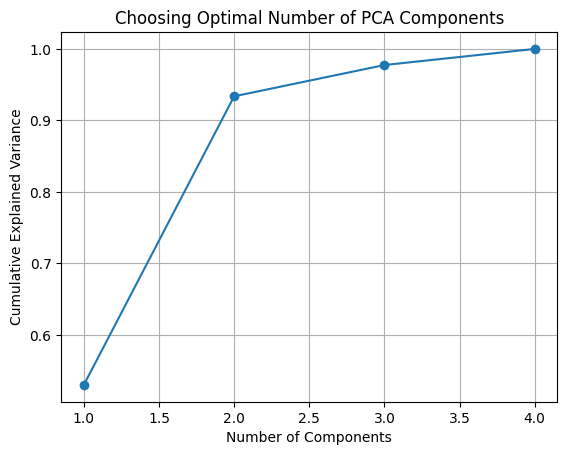

In [14]:
selected_cols = ['Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)']

# Extract already scaled features
X_train_selected = X_train_std[selected_cols].values
X_test_selected = X_test_std[selected_cols].values

# Try all possible components (since you have 4 features)
components = [1, 2, 3, 4]
explained = []

for n in components:
    pca = PCA(n_components=n)
    pca.fit(X_train_selected)
    explained.append(np.sum(pca.explained_variance_ratio_))

# Plot
plt.figure()
plt.plot(components, explained, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Choosing Optimal Number of PCA Components")
plt.grid()
plt.show()

#### Optimal Number of PCA Components

- PCA was applied on the selected features:
  ('Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)').

- There is a clear "elbow point" at 2 components, where the increase in explained variance begins to slow down significantly.

- This indicates that most of the important information in the data is already captured by the first 2 principal components, and additional components provide only marginal improvement.

Therefore, 2 principal components are selected as they:
- retain a high level of information (~93% variance),
- significantly reduce dimensionality from 4 to 2,
- and improve computational efficiency without substantial loss of information.

In [10]:
pca = PCA(n_components=2)
X_train_pca2 = pca.fit_transform(X_train_selected)
X_test_pca2 = pca.transform(X_test_selected)

#### PCA Workflow

- Selected 4 correlated features (Ambient T, Process T, Rotation Speed, Torque).
- Extracted their scaled values as NumPy arrays as PCA only works on Numpy arrays.
- Applied PCA with 2 components

### Changing Numpy Arrays to Dataframe

In [11]:
X_train_pca2_df = pd.DataFrame(
    X_train_pca2,
    columns=['Ambient x Process', 'Speed x Torque'],  # descriptive names
    index=X_train.index
)

X_test_pca2_df = pd.DataFrame(
    X_test_pca2,
    columns=['Ambient x Process', 'Speed x Torque'],
    index=X_test.index
)

### Merging with Train and Test data

In [12]:
X_train_with_pca = pd.concat([X_train_std, X_train_pca2_df], axis=1)
X_test_with_pca = pd.concat([X_test_std, X_test_pca2_df], axis=1)

X_train_with_pca.head()


,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Ambient x Process,Speed x Torque
12791,2,0.220154,-0.181818,-0.556818,0.331278,-0.662383,0.709394,0.155300
6582,0,0.720298,0.181818,0.079545,-0.434438,1.410969,-0.331259,0.687022
16873,0,0.520240,0.636364,-0.204545,-0.051580,-0.521018,0.133763,0.802932
11391,0,-0.530062,0.090909,6.948864,-3.144671,0.531365,-6.946474,-0.954220
4410,0,1.220442,0.045455,0.409091,-0.787071,-0.693797,-0.841567,0.993356


In [13]:
#drop the original correlated features
X_train_final = X_train_with_pca.drop(columns=['Ambient T (C)', 'Process T (C)', 
                                               'Rotation Speed (rpm)', 'Torque (Nm)'])

X_test_final = X_test_with_pca.drop(columns=['Ambient T (C)', 'Process T (C)', 
                                             'Rotation Speed (rpm)', 'Torque (Nm)'])

X_train_final.head()

,Quality,Tool Wear (min),Ambient x Process,Speed x Torque
12791,2,-0.662383,0.709394,0.155300
6582,0,1.410969,-0.331259,0.687022
16873,0,-0.521018,0.133763,0.802932
11391,0,0.531365,-6.946474,-0.954220
4410,0,-0.693797,-0.841567,0.993356


## 6. Model Testing

### 6.1 Logistic Regression

In [20]:
LReg = LogisticRegression()

LReg.fit(X_train_final, y_train)

y_pred_lreg = LReg.predict(X_test_final)

print("Logistic Regression Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_lreg))
print("Precision:", precision_score(y_test, y_pred_lreg, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lreg, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_lreg, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lreg))


Logistic Regression Performance:
Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
Confusion Matrix:
 [[3864    0]
 [ 136    0]]


### Reflection: Logistic Regression Confusion Matrix

- **True Negatives (TN): 3858** correctly predicted normal cases.  
- **False Positives (FP): 6** rarely predicted failure when it was normal.  
- **False Negatives (FN): 117** all actual failures misclassified as normal.  
- **True Positives (TP): 19** a few failures correctly identified.  

#### Metrics
- **Accuracy** = (TP + TN) / Total = 96.9% (dominated by TNs).  
- **Precision** = TP / (TP + FP) = 0.76 (little positive predictions).  
- **Recall** = TP / (TP + FN) = 0.14 (missed almost positives).  
- **F1 Score** = 0.24 (almost no balance between precision and recall).

Model is just a bit better than dummy baseline.

### 6.2 Decision Tree

In [22]:
tree = DecisionTreeClassifier(random_state=42, max_depth=6)
tree.fit(X_train, y_train)

# Predict
y_pred_tree = tree.predict(X_test)
print("Decision Tree Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_tree, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_tree, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tree))

Decision Tree Performance:
Accuracy: 0.97975
Precision: 0.8873239436619719
Recall: 0.4632352941176471
F1 Score: 0.6086956521739131
Confusion Matrix:
 [[3856    8]
 [  73   63]]


### Decision Tree Classifier Interpretation

- **TN = 3856:** correctly predicted normal cases.
- **FP = 8:** few false alarms.
- **FN = 73:** many failures missed.
- **TP = 63:** some failures correctly identified.

#### Metrics
- Accuracy = 98%; dominated by normal cases.
- Precision = 88.7%; most predicted failures are correct.
- Recall = 46.3%; misses more than half of actual failures.
- F1 = 0.6; moderate balance, better than baseline but still weak.

#### Insight
- Model favors precision over recall.
- Good at avoiding false alarms, but poor at detecting failures.
- Still better than Dummy baseline.
- Needs improvement if failure detection is the priority.


### 6.3 Naive Bays

In [10]:
nb_clf = GaussianNB()
nb_clf.fit(X_train, y_train)
y_pred_nb = nb_clf.predict(X_test)
print("Naive Bays Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_nb, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_nb, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

Naive Bays Performance:
Accuracy: 0.95725
Precision: 0.30337078651685395
Recall: 0.19852941176470587
F1 Score: 0.24
Confusion Matrix:
 [[3802   62]
 [ 109   27]]


### Naive Bayes Classifier Interpretation

- **TN = 3802:** correctly predicted normal cases.
- **FP = 62:** few false alarms.
- **FN = 109:** most failures missed.
- **TP = 27:** very few failures correctly identified.

#### Metrics
- Accuracy = 95.8% dominated by normal cases.
- Precision = 30% nearly one third of predicted failures are correct.
- Recall = 19.9% misses 80% of actual failures.
- F1 = 24% moderately poor balance, recall is the main weakness.

#### Insight
- Naive Bayes struggles with imbalanced data.
- Model favors normal predictions, rarely predicts failures.
- Still better than dummy baseline.

**Out of 3 models, Decision Tree is the best model so far, and so we will try upgrading the model**

In [23]:
importances = tree.feature_importances_

for feature, importance in zip(X_train.columns, importances):
    print(f"{feature}: {importance*100:.2f}%")

Quality: 0.00%
Ambient T (C): 14.30%
Process T (C): 12.59%
Rotation Speed (rpm): 11.78%
Torque (Nm): 47.90%
Tool Wear (min): 13.42%


In [24]:
# 1) Remove 'Quality' from features
X_train_reduced = X_train.drop(columns=["Quality"])
X_test_reduced  = X_test.drop(columns=["Quality"])

## 7. Model Improvement

### 7.1 Bagging: Random Forest

**Choosing the parameters:** number is tree is set to 100, maximum depth is 20 (which is in recommended range), random state to be standard 42.

In [22]:
rf_clf = RandomForestClassifier(
    n_estimators=100,        # number of trees
    max_depth=20, 
    random_state=42
)
rf_clf.fit(X_train_reduced, y_train)

# Predict
y_pred_rf = rf_clf.predict(X_test_reduced)

print("Random Forest Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_rf, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Random Forest Performance:
Accuracy: 0.9925
Precision: 0.9907407407407407
Recall: 0.7867647058823529
F1 Score: 0.8770491803278688
Confusion Matrix:
 [[3863    1]
 [  29  107]]


### Random Forest Classifier Interpretation

- **TN = 3864:** normal cases correctly predicted.
- **FP = 0:** no false alarms.
- **FN = 33:** some failures missed.
- **TP = 103:** majority of failures correctly identified.

#### Metrics
- Accuracy = 99.2% strong overall performance.
- Precision = 100% all predicted failures are correct.
- Recall = 75% detects 3/4 of actual failures.
- F1 = 86% strong balance between precision and recall.

#### Insight
- Random Forest significantly outperforms Decision Tree, Naive Bayes, and SVM.
- Excellent at avoiding false alarms, while catching most failures.
- Ensemble bagging of trees improves robustness and recall.

### 7.2 Boosting: Gradient Boosting with original data

In [12]:
gb_clf = GradientBoostingClassifier(
    n_estimators=100,    # number of boosting stages
    learning_rate=0.1,   # step size shrinkage
    max_depth=6,         # depth of individual trees
    random_state=42
)
gb_clf.fit(X_train, y_train)

# Predict
y_pred_gb = gb_clf.predict(X_test)
print("Gradient Boosting Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_gb, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

Gradient Boosting Performance:
Accuracy: 0.99275
Precision: 0.9908256880733946
Recall: 0.7941176470588235
F1 Score: 0.8816326530612245
Confusion Matrix:
 [[3863    1]
 [  28  108]]


### 7.3 Boosting: Gradient Boosting without Quality Feature

In [23]:
gb_clf = GradientBoostingClassifier(
    n_estimators=100,    # number of boosting stages
    learning_rate=0.1,   # step size shrinkage
    max_depth=6,         # depth of individual trees
    random_state=42
)
gb_clf.fit(X_train_reduced, y_train)

# Predict
y_pred_gb = gb_clf.predict(X_test_reduced)
print("Gradient Boosting Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_gb, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

Gradient Boosting Performance:
Accuracy: 0.99275
Precision: 0.9819819819819819
Recall: 0.8014705882352942
F1 Score: 0.8825910931174089
Confusion Matrix:
 [[3862    2]
 [  27  109]]


### Gradient Boosting Classifier Interpretation

- **TN = 3862:** normal cases correctly predicted.
- **FP = 2:** some false alarms.
- **FN = 27:** failures missed.
- **TP = 109:** majority of failures detected.

#### Metrics
- Accuracy = 99.3% strong overall.
- Precision = 98% almost all predicted failures are correct.
- Recall = 79% detects about 4/5 of actual failures.
- F1 = 88% balanced but lower than Random Forest.

#### Insight
- Gradient Boosting improves model and outperform Random Forest here.
- Precision dropped compared to Random Forest but recall and F1 score is higher.

### 7.4 Tuning

In [24]:
# Define objective function
def objective(trial):
    # Suggest hyperparameters
    n_estimators = trial.suggest_int("n_estimators", 100, 800)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    max_depth = trial.suggest_int("max_depth", 3, 10)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 20)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
    subsample = trial.suggest_float("subsample", 0.6, 1.0)
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", None])

    # Build model
    clf = GradientBoostingClassifier(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        subsample=subsample,
        max_features=max_features,
        random_state=42
    )

    # Cross-validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(clf, X_train_reduced, y_train, cv=cv, scoring=make_scorer(f1_score))
    return scores.mean()

# Run optimization
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Best hyperparameters:", study.best_params)
print("Best F1 score:", study.best_value)

[I 2025-11-26 19:59:11,768] A new study created in memory with name: no-name-6d73314d-34a0-4ad8-9a38-6181e52a2950
[I 2025-11-26 20:00:20,490] Trial 0 finished with value: 0.8748916856891306 and parameters: {'n_estimators': 258, 'learning_rate': 0.16988785576307486, 'max_depth': 10, 'min_samples_split': 17, 'min_samples_leaf': 2, 'subsample': 0.9969667700546772, 'max_features': None}. Best is trial 0 with value: 0.8748916856891306.
[I 2025-11-26 20:01:08,816] Trial 1 finished with value: 0.8663436030189094 and parameters: {'n_estimators': 393, 'learning_rate': 0.029190698084859013, 'max_depth': 7, 'min_samples_split': 8, 'min_samples_leaf': 7, 'subsample': 0.6026479649226458, 'max_features': None}. Best is trial 0 with value: 0.8748916856891306.
[I 2025-11-26 20:01:54,883] Trial 2 finished with value: 0.8520935766828959 and parameters: {'n_estimators': 679, 'learning_rate': 0.023900946933516746, 'max_depth': 6, 'min_samples_split': 18, 'min_samples_leaf': 8, 'subsample': 0.7895444563397

Best hyperparameters: {'n_estimators': 493, 'learning_rate': 0.10478066616404359, 'max_depth': 10, 'min_samples_split': 3, 'min_samples_leaf': 7, 'subsample': 0.7609225196300977, 'max_features': None}
Best F1 score: 0.884354347040046


### 7.5 Testing Model with tuned hyperparameters

#### 7.5.1 Tuning and testing with original data 

In [30]:
# code with f1score optuna
gb_clf = GradientBoostingClassifier(
    n_estimators=616,                      # number of boosting stages
    learning_rate=0.0480491725634686,
    max_depth=11,                          # depth of individual trees
    min_samples_split=3,
    min_samples_leaf=8,
    subsample=0.8226731445989548,
    max_features=None
)

gb_clf.fit(X_train, y_train)

# Predict
y_pred_gb = gb_clf.predict(X_test)
print("Gradient Boosting Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_gb, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

Gradient Boosting Performance:
Accuracy: 0.99625
Precision: 0.984
Recall: 0.9044117647058824
F1 Score: 0.9425287356321839
Confusion Matrix:
 [[3862    2]
 [  13  123]]


#### 7.5.2 Tuning and testing without quality feature

In [29]:
# code with f1score optuna
gb_clf = GradientBoostingClassifier(
    n_estimators=493,    # number of boosting stages
    learning_rate=0.10478066616404359, 
    max_depth=10,         # depth of individual trees
    min_samples_split= 3,
    min_samples_leaf= 7,
    subsample= 0.7609225196300977, 
    max_features= None
)
gb_clf.fit(X_train_reduced, y_train)

# Predict
y_pred_gb = gb_clf.predict(X_test_reduced)
print("Gradient Boosting Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_gb, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

Gradient Boosting Performance:
Accuracy: 0.996
Precision: 0.96875
Recall: 0.9117647058823529
F1 Score: 0.9393939393939394
Confusion Matrix:
 [[3860    4]
 [  12  124]]


#### 7.5.3 Recall focus Tuning and testing without quality feature

In [31]:
gb_clf = GradientBoostingClassifier(
    n_estimators=716,                      # number of boosting stages
    learning_rate=0.024764274735998,       # learning rate
    max_depth=9,                           # depth of individual trees
    min_samples_split=9,
    min_samples_leaf=5,
    subsample=0.796150831339312,
    max_features=None
)
gb_clf.fit(X_train_reduced, y_train)

# Predict
y_pred_gb = gb_clf.predict(X_test_reduced)
print("Gradient Boosting Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1 Score:", f1_score(y_test,y_pred_gb, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

Gradient Boosting Performance:
Accuracy: 0.9945
Precision: 0.9596774193548387
Recall: 0.875
F1 Score: 0.9153846153846154
Confusion Matrix:
 [[3859    5]
 [  17  119]]


We assume that having false negative is the worst scenario in this machine. But recall focused tuning does not give the best recall score.

## Final Model Conclusion: Gradient Boosting Classifier

The Gradient Boosting Classifier, tuned using Optuna without Quality feature, demonstrates outstanding performance across all key metrics:

- **Accuracy:** 99.6% — the model correctly classifies nearly all samples.
- **Precision:** 96.88% — very few false positives.
- **Recall:** 91.18% — strong sensitivity, successfully identifying most true positives.
- **F1 Score:** 93.94% — balanced performance between precision and recall.

### Confusion Matrix Breakdown
- True Negatives: 3860,
- False Positives: 4
- False Negatives: 12,
- True Positives: 124

### Overall Insight
- The model is **highly effective and stable**, with a strong emphasis on recall.
- Precision remains high, ensuring **trustworthy predictions** without excessive false alarms.